# Week 11 — Bivariate analysis and inference lab
**Research Method of Data Science · TIC3002 · Fall 2026 · Iegor Vyshnevskyi**

## The research question
> In the available NSW experimental sample, how do 1978 real earnings differ between the training and control groups, and how uncertain is that comparison?

You will work with **real research records** from Rajeev Dehejia’s NBER-hosted data page. The notebook embeds the original text files, so the standard run requires no download or API key. Simulated samples, bootstrap resamples, and shuffled labels are teaching calculations based on those records—not additional observed people.

## By the end, you should be able to
1. distinguish an observed **estimate** from its target quantity;
2. connect a grouped table and plot to a research question;
3. interpret a mean difference, standard error, confidence interval, and p-value;
4. explain how bootstrap and permutation distributions answer different questions; and
5. choose evidence appropriate for numerical or binary outcomes.

## How to work through the notebook
For each section, follow the same cycle: **predict → run → inspect → explain**. Run code cells with **Shift+Enter** and replace each response prompt with your own words. Work independently; you may compare interpretations with a classmate after writing a first answer.

**Core route (about 75 minutes):** Sections 0–5 → choose **6A or 6B** → Sections 7–8. Section 9 is optional reference.

**Colab:** upload this `.ipynb` at <https://colab.research.google.com/>, save a personal copy in Drive, and run cells from top to bottom. Before leaving, save the completed notebook and download the output bundle.


## 0 — Know the study before calculating

### Design and inference boundary
The NSW study provides a randomized-origin training/control comparison. This teaching subset contains **185 training participants and 260 experimental controls**, selected using pre-intervention information. We do **not** use the nonexperimental CPS/PSID comparison files.

Participants were not a representative random sample of all workers. The public files also do not reconstruct the complete assignment protocol, blocks, or attrition history. Therefore, interpret the calculations as a transparent comparison within this available experimental subset—not as automatic evidence about every worker or as a complete design-based reanalysis.

### Variables used most often

| Variable | Meaning | Role in this lab |
|---|---|---|
| `treat` | 1 = training, 0 = control | group indicator |
| `re74`, `re75` | real earnings before the 1978 outcome | baseline variables |
| `re78` | real 1978 earnings | primary outcome |
| one row | one participant | unit of analysis |

The data source calls these *real earnings* but does not state a price base. We therefore report **source-dollar units**, not current dollars. Recorded zeros are valid observations, not missing values.

**Planned primary contrast:** training mean minus control mean for `re78`. Other analyses are exploratory; do not search for whichever result has the smallest p-value.

**Sources:** [author data page](https://users.nber.org/~rdehejia/data/.nswdata2.html); LaLonde (1986), *American Economic Review*, 76, 604–620; Dehejia and Wahba (1999), *JASA*, 94, 1053–1062.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import base64, zlib, json, hashlib, zipfile, sys
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() / "inference_lab"
RAW = ROOT / "raw"
TABLES = ROOT / "tables"
FIGS = ROOT / "figures"
for folder in [RAW, TABLES, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 160,
    "axes.titlesize": 14, "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10,
})
CONFIDENCE = .95
B = 5000  # Monte Carlo replications, not new observed participants.

def show_save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

print("✓ Setup complete")
print("Working folder:", ROOT)
print("Python", sys.version.split()[0], "pandas", pd.__version__, "SciPy", scipy.__version__)


✓ Setup complete
Working folder: C:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W11\inference_lab
Python 3.13.4 pandas 2.3.0 SciPy 1.16.0


In [2]:
SOURCE_B64 = "eNrtXUuPI8eR/ivEXFcqZbwyM+TTYnXZiyGsFvBhtRDY3RxN2z3dA5ItyRC0v30ji01W9mOSVaznCPbBcrmpYjAy4x3xxe/v7ne/bjeBf7p+uN9vH+6q/W/7d9+u3q1WrnKH/2z+zf5rtcKKmmdYrSD/+8tn9/rff/nc9fPPn3+8f4tC/4IifPbsen1jm1+EFMnH+pnfpvA5RdqTJ8PzEKo4K4X2+cDOFXjIlbw4ZZj0Htr3BfUcPk/h3DzUCjE4wfqZ3r6H/IzC2Pvmd/68eMUCD+kFhV1PGXpS6CvHjkja85B78qgrhVTF6CLR5ymkV/pweRr75alyLwq7PksVgjhflJS4cI2NVXhGYeh578awKVqUZbcAHrqiPpz/lF/rQ5xUUkxSgQJ2sClTa5tQeYietEQhdrJ6MLhdVnTKRZsyr2/DFainICWboov3YPtRCL1/kfcSUUoeLM/sHyZBdlS6h2FWfUhVsEDKu/aSMj2FAqKoJUmBWfUh2BkCi3bxsd2kPnZ3/zBMrLHb2GWa1S5LpcGhhM/fw5fR6MtTHpuH9v2i4ENJln0vHvblsTerB8rURZanPeVQYWRSLlEos2obs2kSyR20DbbxsafmYRttM6/3dQmFU/vYZILMrss9XB4P3aw8tO8HkbL3JUX/cHyNLUEt3CvlscPMvg2QcCj6h65TzmFoHvqKQgzoulg9mFiWIVjEHEqyHL+4rMjU+lAFpaQPX+e+lmb16ExWZIJ7KAiE7WV5an0YK0KNWNTYS6+N0pkoYHyNjYyqULIpvHjPgWalUCoXY/AdrN7U8TKb1eOif/i64jN19VbEpBm65GCXVzXDWWujUHm1WI+76MPlyTLP3CsCqOyLPrZ+cTycWpbZ47His8h+G7tV0USl2BEUZ7YpwQcodRHMnT/0laCFo9olkppWY1OlBPh0you0KeYXKCNyF+9r6d19ssBo1M/sY7NXR9JeH34JGc5p42WqGKLT0L42OkP/IWggbu85xAX2LM3bzXKJj+0W7n2FyX0bFjF9U5KUeXNf5rmoUwqX99t0jZwuqJpF8eBLOVg3Mw/JA3WxKXHye2gRgLiCfygvTpkmplCqyBTUd6lWTKttYiUapdTdRzPHeph650A7dPctP9N+LucAg/c5BBJCt9yepeXPp5ynUM7I8vw9S337HAawekGED/oQxqinwJ++njJ+rwj07+F0EKFgU3hmH9tXSo7It+92nrozzXioElS72GWalEKpQAk5tJ8LmDpOwUShYCzxcN6sSIro0Umnfhua1LcJlXcqEJebg7VTtlgUQ0nbLL++PPdkK3rGcieGLNzHfl1PmVZjXxIFLL++vLwoYN4pJKkCmKzQeJEU/Om7WS6ZrViexp69DzZyjNglBzt1r4hDlFisgC8fV0R6aZv+8XIAoQBLri9HDVGL0x/Lry+Xu53d6DlYUMcI7X1sP7HV4yoCOXFdqhU8qfcVKmL2YcROjCns8rwae/waPcwQBUwbLy/f++KKUs0slKpm88bLwbQNnqlJUbEjaAmZdjdrbZQqb/pQpJQV6efbDGBTmKOj9jlYv8Buln7zy3Nom+V5X2HmfmwOCc6hhJZARUkZu1dk+RWf7vdwBlwRcw8dtO92nr6bRXwEKU4UzovNEirjHzO3n3nU6ZHxAHyky095/AlrFzSKb48hOb1/6CVgoPb3cGoKYyUCUp5c0FmtnvnYTmMpGp2bQqkwQab59pIywwQNRw8LRlu1z8cQSh2SMHOvCKYcbHyq0WM7WZ6aQtM2wUn7exgmj1OAMNHYYU5q8i4CcgRcuoe68M605Xf3zS0py6cQK4jK6LtYPVg4D2fAx0Zwqsu1KenMOJZw2r88WZ46koqVKkUv7SXFTxyniMUpEMvxcjebMnxED8pG4OVxyvLQp6fvZgElF7U9D/9ll9/IX4p4D+19bJ089yWp3oNftl3uFy/372bBoMGHUjfLvLJs30+iwMuN6LGiqD7ociOp/tpmfEQyTutT5M/kY8/gwTJRDJdbvfG9LwCOXWR5evzDCIhPfbDYBu9raG0jlSm7I64cvlm1Yzoin8zCw1TRIeQnffcWGr93xkKdT5ah8uj9Ed9wCCyCoU/ZvKsYWePnKLRfwB4kXI6z1Ld6SxUHVP4shb4KATzi5VgE/SUFTViP20fGQOPvS6HJalDVp0z62zkHKJ4yTWz1YkXenBl++xa1wwgat1cEKkbSpzoeLhGbBRL2wKk6cZnnMOwpaxUVj12kWGsXQRdOFHKFAoBhPpuSbAajP1GYzgycD81zVPA+LsdzwIQ9IE9bcbDG5DD3y0v7zWvD22UOgHqyeiaZIeITrlJ9ylFiVOmCBEWD9iyZxjYeOX+kkKtg6htiRiGgBH/53oqhu6i4Uk5jUV20zbQIjVI5U9dPPMPDnkfQWKiNTo2JYafu+IgMigecJQzlCZp+s7fnfBtvkZKj4waXWnZTxZu7aOzYKZLqz0NRUX+6hyFJ5sl/nKMf21eUEMS14WF0QR10kRQ3qV1OkVUEgUbbgGgRh3PqbpZaduUpcrroHg4fSZl28Xo6ZV/LLlJj9ViDKHSpVozNQ88nFDccolMXBs8xiHmw3SRlXP+Q7JQFjtuYanQEjxp9FwrjpHY5Vo4os8spXg7HWsAsuMTmsZKx8CQpsfLEQaULD8e1yyYZ3nzqk39oHPBIx13BdazJkUqoHWNnic3bchaIaE5hVIfZs3mPGLp4DsOeMlemDPUZD8MpW1frRx/QlWcep530T5Jolvok25r2+HihyzW26z0tbBR5l52yqUOPsfEknIUp0XdBxhv2lEPKwQJBQyEhnLZ31reMTrMVtAQk+URh0Cb2U7PLoq7DDpqhvS/zWIPXmOUcKAAHanjoohJAl46g0TNLTgTw7XziJafsetsU7zWgNPeQfaSYaR8TpAQTVNCHMGqcYtosRoZMQ0tKC4fmOXAZ5ZImnihM2s17Ce1PmUbe8AIpkw7HeLh+Rs+fy2vPo7E5JecyfWjBskgWFZAwaI8Jmr48jCaJevQMDhSGeOoAOuyGg+PnF7HhJWE5e9fUqJK+rFcAzoYHyxbR24tCpqFNvUTXZOvMTMcIpdrouPjYxoEo+jSpxQcbYjYu8yS8+lO9ZQlIUFj7hyLNKZOR38U/HHrS3yTBvEHFJrOOXiRoc+pmcAhn7KoKFQKx81ktwJRNI8tqso0YaTndfZiyc+hDF409di3ArLC47FR9RMBONmVcWTaNDeGkkev43HxuzXydgGU8h5ce7NBz9Ol9PuaSEcV5cF08BxrZc3CCR3+QD1UyjegaHkbTl1FL9WXfq4vgfI2emY6ZdTpkmug0QXiIW1h4xi4C81jtnh0nE2oKAwb02amzl8ilPthx9WHaQG1OdMZDs4KZXa73p4hSe0SyoX3sYLLKGLPKIzty4vt4sEPnbcxTCOQaCtP6AtT2FPLIiBPpnmP0sfG2ACMzNR6seCnOL/fNfXXtJeaE1ReoU7wcJqaQ1QIr7mP1Bq+aUTh6X3RAqyHnuQsP46g8TJszCHwWl5BSbOwyVxpYytm5cRFrk9WLAierJ2lunhttk3rajQJsnyUeWh+mXZj+lB+sKfQoTbcfpQqQhHh5n8PwtVEPpE673EMaOQrwELLqREKoTY0OWe4LA0duP7kwNA+fRVJ08Bc5YKbBQ9CAbryOoPOyjErUZJK8eWOppTOPly2gj136D4eWZQ1RnmwI1/UTF4FCpm0UJWD7fuw4eA+nSnA+PqPwtCu49hcjSYT5qhXRIifnmujTJw3NMaMwuBjK+0bdyBQ6p+Cf1ZctspLsWRTLaPwwapyC9T1r4pSYtjNxgLxaYQqbu6D+Yi8K30DoRvDqMwq9XcuMpy5EKCOFjpuD1Qp9VM5qUGAUKl3u2wyNS1xjNyPDUZaN4oT8FJ5VImMJCYp6SkpXD1YrsuCOMs/B4vvi/PLYmGkWsQvo0z5RPlCoJ/SsZXiwyBSjNpVHI4wU3u7CvyRL7AaY/vD8tKeHDx6tRn/iaUjbjbXkOXDP+ZTzp4zoXchqUkn/ITfP5sAqweWVx/522SK748aCI0UBscspj907Z5EesDQUWux3zMHyJcjJQ8/rqcV6xsEsG+eJAbJ7mRrpyJVOeVwkeaw4WDSKOUXsPTWSQkzHeRUaQ5bPU5jcU8UmB5tAizQ20an5YpnGfvfV6t397tftJvBP++1mvd/cVPvf9u++Xb1765JPmzB5bX409RlnwT50bHcfHxpRVGJeeoaFLZy1K2yBNWdFSVjYAu5QpbpG6ZRpZpjT1+sYYOaxi9cG2Ynn0j08FyBMD6oMC1sbF9PIKUhsr22gNCgyiiynKDYvjsPZkh/2MjfuAnhJC6TD57XN3KumYgWB1BVPGUZtgXAtWsTS2FeJh/OCKp+X5b6LnPoDy0Q75bwoCWdKfmFy+CCHFHPYFlgYmK3pY4ySrxKAjgOb40sKS4ToS77NvED9wQIG4rzx743S8Kx2OYXWjglLPPRzUxj4GSAwzNw82V0f8iuKeNQBpTegb1glT9zBmQXcOjFEpzeOpDpvSdvMu0DH9HECAnMljT07iCh4glCSlHmXYWnlGVW1dMrzLu1NYBXBsXaxesO2u7c5ZcYY2vs2099Dn8ppXLqHPPMpp7Kqw89H9MsDpn5tU55rG57Yg/X1wgjF8WS5fxQggRmLWZF5va82kdS8K8ITIDAEoZIHi0XfZvysiBMnpVjvJQ9lckmBmCasxsvOwQDgFCACpVPu17QG/eNlZRDfxT9cmsbGidvq3sjOiUXM2D7nMHUUABWZoMQOeZvpQeZTsSJK+ygg9m8b6agPQwxHsJ6WVm9a74uqNFbMbrmew3lZnvsedqdQF5glntcumz6EGBi6ZJam1dhpnasF9EWrt/RaQN8Bduivse2Qc2BqWDxA+tKiAJMDjhqoS5/DtKdsHmzqQI1fckRPM2vsBLcWxPlSFAC9cg7Qu56CCbfajxeN9q+AExgTi/UU7NRMPsIpczxWfOjL9G1e5rGnXyusSKfG6LdlWWbVNpyGHJB8lzz2tFYvgTei5qPN50556gxnqDzqsTMN23hfc2hsZdTldve1kWUqdmK4BWTa+8Up/T1YYR9ASrI8LmzLeUnhoF46aJvlRaP8qs9hWh761H/oStrmZZziFx/RT5/hBLuGsRjRv4z1ZFIK09BDFIbLc1/j+4cxRCr32+DMpxzTOolYohAWr23mzcHWVle8uzxOGb9qxpIAKLtIytKqt1ODiL5xygjgQvu+r7Ghs99acQGxW78NLeyUcfHxMn0BGU7qVTXrX5OKMUEele6hn5WHCZKOnPr2Vm9qWY4ps+TLHePyr2rF2Z5212lyYYl9DrJ4bTNvJ4ZWGimUtA3P3CHZP9Ybv6ddEogLta/rTT+VydFMinSpVkw+HSwehLr42MurmnUDmYfBIykfU4m+S7fz8jS2n5XCBN4jx6Vsi5wLSOsLETW2z87NQCGwx9BlonDqSf80r+eK+pAW37M0bzSawG1VMbb3D6evSakQ+jher8jy9eF52BaXFuZo++XR53o4hz5ln4AFVflzFMYUL3sv7bsIhrbL5l0JBMfNUkomPsJN1tURrHf4zjf9cW7x8SX5w6GhESWiMDXLDhKULZ2WH5hd1hipiHwy7vrCtEbYxZCtiSN2rNSeh2NnRT5DITenjiLRYZca/dCLS8AEAzKAdAnKqtkSDvCExYqPmzROoSoE8c0KyFpyPHXybcb1YCn5g8feYaxxRZDP1OjH7SWWhKOUwalJ5cBlFPoqAFGpQ/J1F8G4k1w+weBni4/NYpgLq7E98snYpxyqtL8iaKMPA9kh8+UTNGNTaDz0USB20Tbd1qy3AA2NID6DihUKiDKc1XO9wRvr1fSQQcXqaQlRvZqZ0DwLGa+b5QIgVmaWXFJMbpC6YFUNrW18wsHHbLGnhxA62WUa1cd+g4eeKbcpgEToL5/+6J/1oCiBn61SCUzZUvO0boywpLHHjaRMUtLCiAyiE9HigmzZgYvC7C6PAoZeNZW8LXrGQ5MbdK79BM34q/dSmTFk6wsd2SN1QeAZtyZlFkExCuWLP9PO3PkmChM0LMQciJUjZ9Gpr5SJGMdDj2kJ+5x7rN5D43OznTIGV8yKTNuzVK9f8M9WWpAnDO31Yex9qmcr3kAg2QpIpFQCnw+B5ymSyleRRrYwINfgDKRdEHiGtctJI8fjMtRaUiIELC0h6qpthu4/xAT2jT6zKWRmsYzqxqNKivmDaRVqthwQTbJDtoQopq2aOl9n2mElbtAG9pmdZvewzSmPW5MyWU1747DhIaNdy0zb2IlLSR/yyGuSTN968RIbCs3bCkjteUgT99uYZAKcFpXUPI0WFOh8FZ9kEcTl6wo9CAafrZFj78s1+mknuYxCsdAuNHGLpv06MN+cVIrUvHKmbdLkVhhQYw/tHxpHhD3np54i/NglfzistkkTORIoW5gTLBbNFx/bvYSoXaKAcTNL9n3kT7O2B5wlu5nQxYMd2qZQMAokW+dqro3PfGzwoSgpY8tyumeemrjEfClKy+qzJZVkOhzny8H6ChPgK2TruUhPWCw1xrgxlbR9R9DYmSWq1xlS5tFiWnHeybehge8hkkelbCWuuuKiz7n7vtJK3EBBnmXez0SjMPI95EA+X4lLhOyyJeZkqobC5SiXAyyPdgCc6T/T1i5IF6s37uq9l9VbsnhZombLATGohw45WB1cH4LazQsND82mnNAR6l4Rj+K5fc5h6AnrWAkEiZplQbCeSDlpbEr1Zx0P1e08uhYER0/LrrimMEQQ7HIPp608ckXaICVfRuHQfQ6BI8VMMmKISnlmSc21gPZbIYZeefa6ekFpEV+WNbZ7qB67UNhtBSSc9WAZ+YQrVz97io4a7yvEyJ7myx8mHPYkK9niYwiRsyqamCfhoEtNamhZZrN5nFXAJUbvs+wcWZSCM86Nml0GzyFbzRxYiTJ9yGTRn58PxSj5f2aWMx4GpazOZzxFPNOp229fAJydMmIXw7PVzGrqJ/NgTZKUO6D+Dt2Z9nJ9oVRpUIFzbSOn5YGzdLNwBSkbl9egxAfplXMYOtMuaho5W3xsl06bbJ09J9eH2mOzDF+TMgIdZjyMAWKzCL4ND7FXffm8p6CI5KTpkHQiocnJpn/fHMhC5ZEm3qwR0mS/gm94ihGYevQ5DNCjJJpVGk37iIjjvN5s4Sl0qfi4Xl0E5/WjxfO+yR9KBYAO+PKtYdA711V3O2erSBOWM2XPooLlCRrp1Zl2PoJPR+pCQxEYDyU0OQhzI7xKSVLGXUVqNsM7zBfOkgmuz1fimreooT2FcXgKU5Ym42Ewrx+k4WEwZwxjl3sIg/uH/iSr9a0CxmatMCec9ix/mJalflzf377f7PbV33cP92lN6u+J8h/f3az3691m/6P9Xz++++t6f/twv75b/fD46dPDdr+5Wf3tYfuP1ea3T5vt7cfN/d7+tlt//HS3+Wr13ebD5u+366//tv5wtV7tHq/q13x1eO3u4XF7vfnp0/rnzeHVH/b7T7tvv/nmcbfZ7qr7q822etj+/M3/bW8Or/kmEfJNdb/7Nf0PrD7sP96d3rbd7Le3m182Nz897q8P70OH/muAr53/bwffCn5LqWKc3BX7zd+anXpByf3D/omSf3/cf3jY7laftg+/3N5sVmbrVk8rZFfr+5uVveP5D75+uN9vH+52q93mbnOdPva4u73/2V6w+fr2fr/Z/mKfM76tbu/fP2w/1jysVt89rOw7Vx9vf1vtP2x2m9Wvt/sPq//4/odvvv/hP7+zv92/+SXVifDNentvX7P76fH+dr870P5fG/vo8Q/2fenVq8MvXL2/vdvsvlrdPNzdrber3fX6blOtfjj8LZ2D/WWzq2nafdpc377/52ptP+HW/nplN+Av9uf6jzUrVuvd6vpxuzXanl6YEfa4s7dlDP3+8eru9nq1tR+53l5/OBCy+vSwS6y6+mdN4/qJ6TUT7Gd/vN3tEstuNrvr7e2VfdAedg2xf7HX7df2A9d7O/qrxwNP/2okbn5dXd2t7/+x2a/sWzf3xtnbndFr9yotAT5RWVORCPyf9Lxa/X74x/FPB9KPK4SfuJ9WCD+94PDJx+1dl+t77nW7D2sUf3jjGsjz9WbNojcqdHPtFdbehxtVk90rXt8QyY2/MSNNwu83SGu5wZtriTcB9Up+fHd47x9ftfh92YrkIX7f516X/75NuAqM7zfu/XsX1u49ywaMbn7/Hly8ulIPcH0T6cbsk2NTuNcc13Ht1rQxvXWzptPvS//43x/v/3j3x/8Da/KITQ=="
source_files = json.loads(zlib.decompress(base64.b64decode(SOURCE_B64)).decode())
for name, content in source_files.items():
    (RAW / name).write_bytes(content.encode("utf-8"))
manifest = json.loads((RAW / "manifest.json").read_text())
for item in manifest["files"]:
    assert hashlib.sha256((RAW / item["file"]).read_bytes()).hexdigest() == item["sha256"]
COLUMNS = ["treat", "age", "educ", "black", "hisp", "married", "nodegree", "re74", "re75", "re78"]
frames = [pd.read_csv(RAW / item["file"], sep=r"\s+", header=None, names=COLUMNS) for item in manifest["files"]]
data = pd.concat(frames, ignore_index=True)
data.insert(0, "record_id", np.arange(1, len(data) + 1))
data["treat"] = data["treat"].astype(int)
data["group"] = data["treat"].map({0: "Control", 1: "Training"})
assert len(data) == 445 and data.groupby("treat").size().to_dict() == {0: 260, 1: 185}
assert data[["re74", "re75", "re78"]].notna().all().all()
assert (data[["re74", "re75", "re78"]] >= 0).all().all()
print("✓ Source files verified")
print("Observed participant records:", len(data))
print("Group counts:", data["group"].value_counts().to_dict())
print("Earnings zeros are observed values, not missing measurements.")


✓ Source files verified
Observed participant records: 445
Group counts: {'Control': 260, 'Training': 185}
Earnings zeros are observed values, not missing measurements.


### Checkpoint 0 — Identify the evidence
Before continuing, complete these in one sentence each:

- **Unit of analysis:** …
- **Outcome:** …
- **Comparison:** …
- **Population you should *not* automatically generalize to:** …


## 1 First evidence: a grouped table and a plot
The table gives observed earnings summaries. The standard deviation describes variation between people; it is not the standard error of a mean.

Zeros are meaningful recorded earnings. They remain in every relevant calculation. A few high values can move a mean, so inspect the distribution before interpreting the difference.


            n     mean   median       sd  se_mean  zero_earnings_pct
group                                                               
Control   260  4554.80  3138.80  5483.84   340.09              35.38
Training  185  6349.14  4232.31  7867.40   578.42              24.32


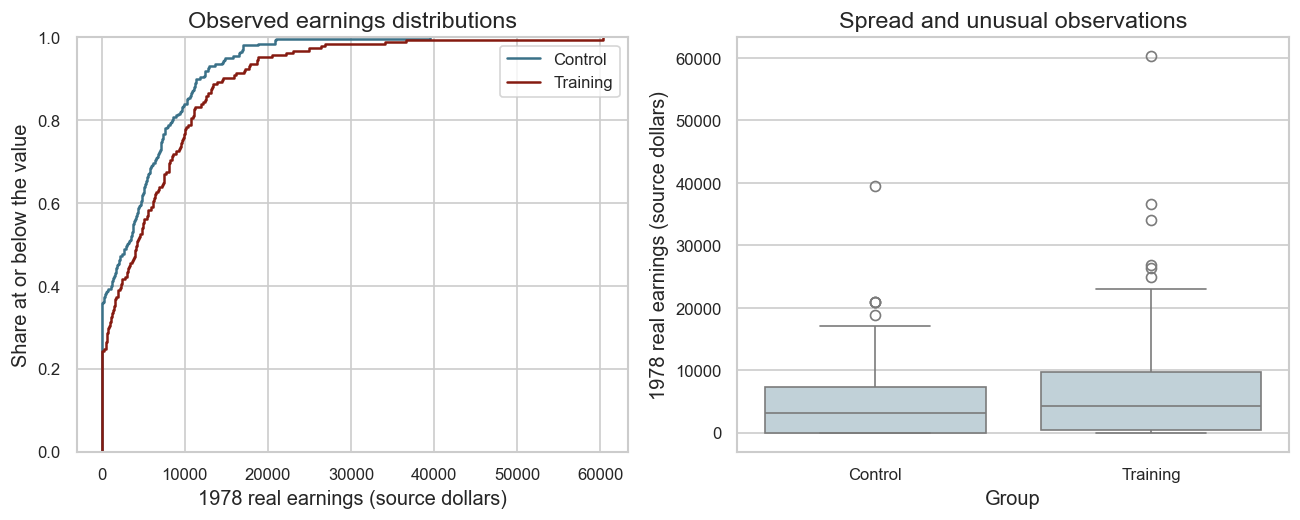

In [3]:
descriptive = data.groupby("group")["re78"].agg(n="size", mean="mean", median="median", sd="std")
descriptive["se_mean"] = descriptive["sd"] / np.sqrt(descriptive["n"])
descriptive["zero_earnings_pct"] = data.groupby("group")["re78"].apply(lambda x: x.eq(0).mean() * 100)
print(descriptive.round(2).to_string())
descriptive.to_csv(TABLES / "01_group_descriptives.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for group, colour in [("Control", "#3a7188"), ("Training", "#851a10")]:
    x = data.loc[data.group == group, "re78"]
    sns.ecdfplot(x=x, label=group, color=colour, ax=axes[0])
sns.boxplot(data=data, x="group", y="re78", order=["Control", "Training"], color="#bdd2dc", ax=axes[1])
axes[0].set(xlabel="1978 real earnings (source dollars)", ylabel="Share at or below the value", title="Observed earnings distributions")
axes[0].legend()
axes[1].set(xlabel="Group", ylabel="1978 real earnings (source dollars)", title="Spread and unusual observations")
fig.tight_layout()
show_save(fig, "01_group_distributions.png")


### Checkpoint 1 — Read the descriptive evidence
 State which group has the higher mean and compare mean with median. Explain why a large standard deviation does not automatically make the estimated mean difference uninformative. Replace this paragraph with your answer.


**Your response:** …


## 2 An estimate, confidence interval and test
For independent groups, Welch’s method allows different population variances. We calculate the training-minus-control mean difference, its standard error, an approximate t confidence interval, and a two-sided p-value for a zero difference.

The confidence interval concerns the **mean contrast**, not the range containing 95% of individual earnings. Under its assumptions, repeated use of the interval procedure has approximately the stated coverage. A particular interval does not assign a 95% probability to the fixed true mean difference.

Our statistical model supports a simple comparison in this study setting. A p-value does not repair sampling, dependence, measurement or design problems.


n_training        185.00000
n_control         260.00000
difference       1794.34240
se_difference     670.99655
df                307.13249
ci_low            474.01047
ci_high          3114.67434
confidence          0.95000
t                   2.67415
p_two_sided         0.00789
cohens_d            0.27272


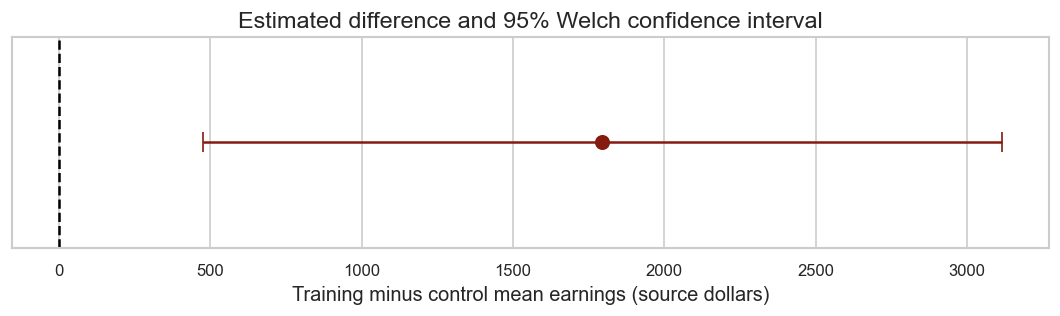

In [4]:
# 1. Define the calculation
def mean_difference(a, b, confidence=.95):
    """Welch mean contrast a minus b; inputs must be observed independent units."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if len(a) < 2 or len(b) < 2 or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Supply at least two finite, observed values per group")
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    if se == 0:
        raise ValueError("Contrast has zero estimated standard error")
    df = (a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)) ** 2 / (
        (a.var(ddof=1) / len(a)) ** 2 / (len(a) - 1) +
        (b.var(ddof=1) / len(b)) ** 2 / (len(b) - 1))
    estimate = a.mean() - b.mean()
    critical = stats.t.ppf((1 + confidence) / 2, df)
    t_value = estimate / se
    p_value = 2 * stats.t.sf(abs(t_value), df)
    pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return pd.Series({"n_training": len(a), "n_control": len(b), "difference": estimate,
                      "se_difference": se, "df": df, "ci_low": estimate - critical * se,
                      "ci_high": estimate + critical * se, "confidence": confidence,
                      "t": t_value, "p_two_sided": p_value, "cohens_d": estimate / pooled_sd})

# 2. Select the two observed groups
training = data.loc[data.treat == 1, "re78"].to_numpy()
control = data.loc[data.treat == 0, "re78"].to_numpy()
# 3. Estimate, verify, and visualize
welch = mean_difference(training, control, CONFIDENCE)
print(welch.round(5).to_string())
welch.to_csv(TABLES / "02_welch_mean_difference.csv", header=["value"])
# Cross-check the hand-built function against SciPy's maintained implementation.
scipy_result = stats.ttest_ind(training, control, equal_var=False)
assert np.isclose(welch.p_two_sided, scipy_result.pvalue)
ci_check = scipy_result.confidence_interval(confidence_level=CONFIDENCE)
assert np.allclose([welch.ci_low, welch.ci_high], [ci_check.low, ci_check.high])
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.errorbar(welch.difference, 0, xerr=[[welch.difference - welch.ci_low], [welch.ci_high - welch.difference]],
            fmt="o", capsize=6, color="#851a10", markersize=8)
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="Training minus control mean earnings (source dollars)", yticks=[],
       title=f"Estimated difference and {CONFIDENCE:.0%} Welch confidence interval")
fig.tight_layout()
show_save(fig, "02_effect_ci.png")


### Checkpoint 2 — Interpret the primary estimate
 Report the estimate, interval and p-value in plain language. Does the interval support the claim that the contrast is at least **2,000 source dollars**? The 2,000 threshold is an illustrative classroom benchmark, not an estimated programme cost or a policy recommendation. Explain what information would be needed for a real cost-benefit judgement.


**Your response:** …


## 3 — Sampling variation and interval coverage
We cannot observe repeated historical versions of the trial. Instead, use the **observed control earnings as a known teaching reference distribution** and repeatedly sample from it with replacement.

This artificial world isolates one idea: estimates vary from sample to sample. It does **not** recreate the true population or the original assignment process.

### Predict before running
When sample size rises from 25 to 100, should the spread of sample means become approximately:
- twice as wide,
- about the same, or
- half as wide?

Write your prediction and reasoning here: …

Then run the next cell. It also constructs many 95% t intervals from samples of size 80. Because earnings are skewed, the observed coverage need not equal exactly 95%.


 sample_n  replications  mean_of_sample_means  empirical_sd_of_means
       25          2000               4511.16                1096.00
      100          2000               4564.70                 536.01


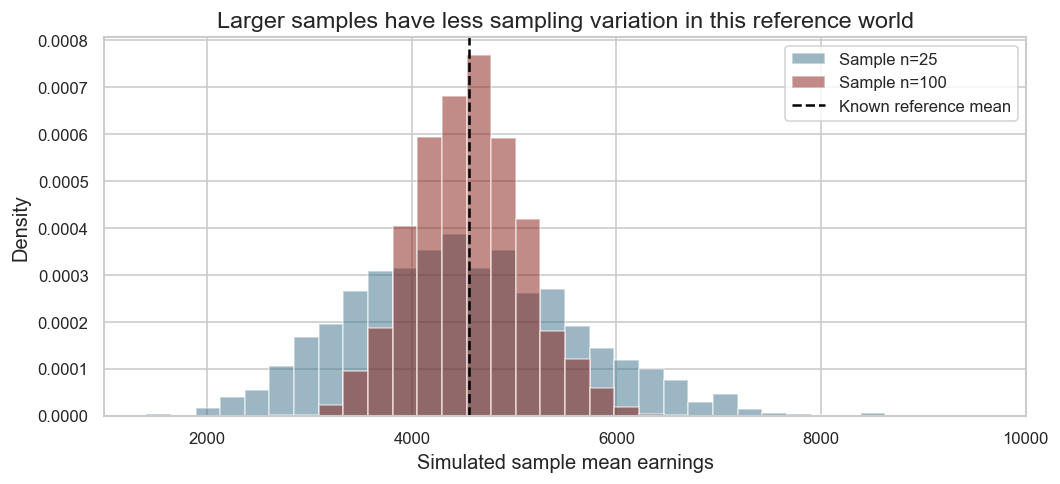

Observed coverage of 400 approximate 95% t intervals: 95.0%


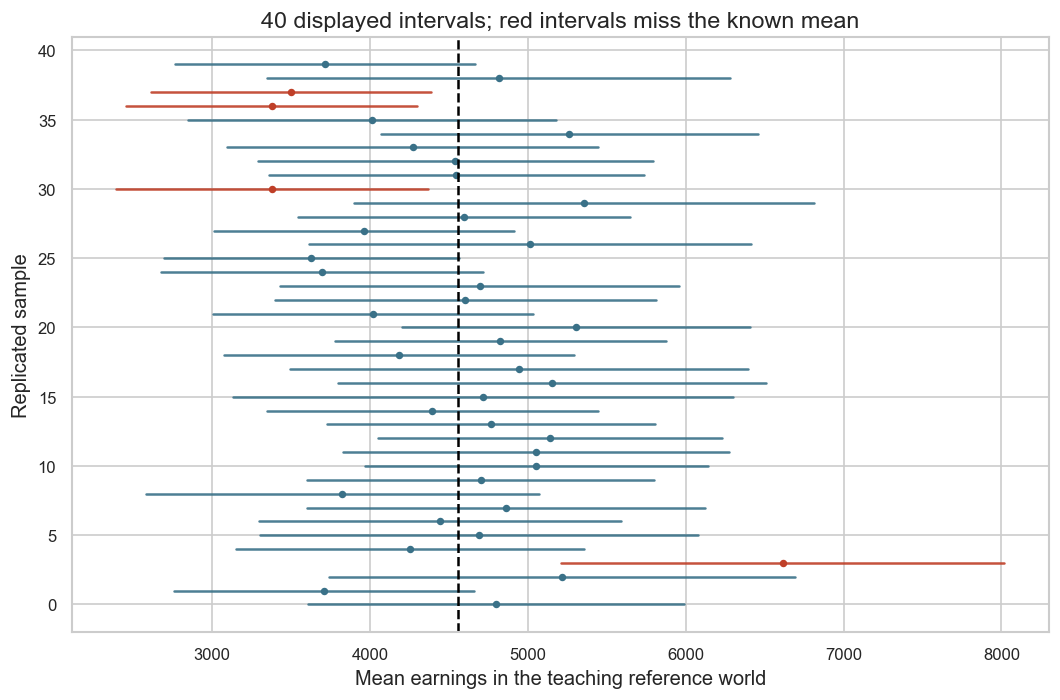

In [5]:
reference = control.copy()
reference_mean = reference.mean()
rng_sampling = np.random.default_rng(1101)
means_25 = rng_sampling.choice(reference, size=(2000, 25), replace=True).mean(axis=1)
means_100 = rng_sampling.choice(reference, size=(2000, 100), replace=True).mean(axis=1)
sampling_table = pd.DataFrame({
    "sample_n": [25, 100], "replications": [len(means_25), len(means_100)],
    "mean_of_sample_means": [means_25.mean(), means_100.mean()],
    "empirical_sd_of_means": [means_25.std(ddof=1), means_100.std(ddof=1)]})
print(sampling_table.round(2).to_string(index=False))
sampling_table.to_csv(TABLES / "03_sampling_variation.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(min(means_25.min(), means_100.min()), max(means_25.max(), means_100.max()), 35)
ax.hist(means_25, bins=bins, density=True, alpha=.5, label="Sample n=25", color="#3a7188")
ax.hist(means_100, bins=bins, density=True, alpha=.5, label="Sample n=100", color="#851a10")
ax.axvline(reference_mean, color="black", linestyle="--", label="Known reference mean")
ax.set(xlabel="Simulated sample mean earnings", ylabel="Density", title="Larger samples have less sampling variation in this reference world")
ax.legend(); fig.tight_layout()
show_save(fig, "03_sampling_distributions.png")

rng_coverage = np.random.default_rng(1102)
samples = rng_coverage.choice(reference, size=(400, 80), replace=True)
means = samples.mean(axis=1)
standard_errors = samples.std(axis=1, ddof=1) / np.sqrt(80)
critical = stats.t.ppf(.975, 79)
low, high = means - critical * standard_errors, means + critical * standard_errors
covers = (low <= reference_mean) & (reference_mean <= high)
print(f"Observed coverage of 400 approximate 95% t intervals: {covers.mean():.1%}")
fig, ax = plt.subplots(figsize=(9, 6))
for i in range(40):
    colour = "#3a7188" if covers[i] else "#bf3f28"
    ax.plot([low[i], high[i]], [i, i], color=colour, alpha=.9)
    ax.scatter(means[i], i, color=colour, s=12)
ax.axvline(reference_mean, color="black", linestyle="--")
ax.set(xlabel="Mean earnings in the teaching reference world", ylabel="Replicated sample", title="40 displayed intervals; red intervals miss the known mean")
fig.tight_layout()
show_save(fig, "04_interval_coverage.png")


### Checkpoint 3 — Explain the simulation
1. Compare the empirical spread of the means for *n* = 25 and *n* = 100 with your prediction.
2. In the interval plot, what does a red line mean?
3. Explain “95% confidence” using the **long-run procedure**, not a probability assigned to one fixed interval.
4. Why is the known reference mean in this simulation different from the unknown target in the real study?

**Your response:** …


## 4 Bootstrap uncertainty around the observed contrast
Bootstrap **with replacement within each observed group**, preserving the two group sizes. Each replicate gives a training-minus-control mean difference. The distribution is centred near the observed contrast. At the default 95% confidence level, a percentile interval uses its 2.5th and 97.5th percentiles.

This estimates uncertainty under an independent-within-group resampling approximation. It does not create new participants, make a nonrepresentative sample representative, or reproduce an unknown clustered assignment design. Percentile intervals are approximate and can be inaccurate with difficult distributions or small samples.

**Prediction:** Will this distribution be centred near zero or near the observed difference?


              method  estimate  ci_low  ci_high  confidence
             Welch t   1794.34  474.01  3114.67        0.95
Bootstrap percentile   1794.34  521.84  3186.32        0.95


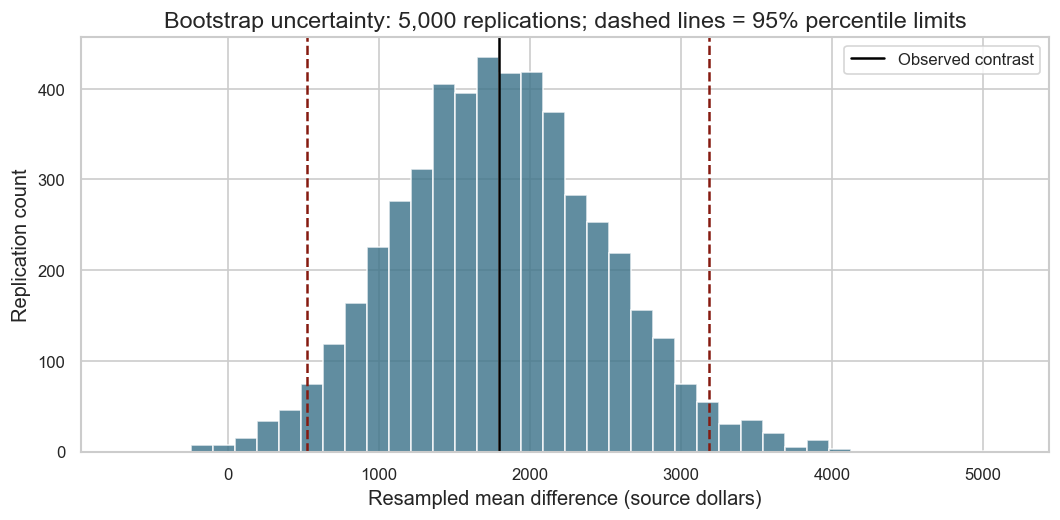

In [6]:
# Resample participants within each group; keep the original group sizes.
def bootstrap_difference(a, b, replications=5000, seed=1103):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Handle missing values explicitly before resampling")
    result = np.empty(replications)
    for i in range(replications):
        result[i] = rng.choice(a, len(a), replace=True).mean() - rng.choice(b, len(b), replace=True).mean()
    return result

boot = bootstrap_difference(training, control, B)
alpha = 1 - CONFIDENCE
boot_ci = np.quantile(boot, [alpha / 2, 1 - alpha / 2])
interval_comparison = pd.DataFrame([
    ["Welch t", welch.difference, welch.ci_low, welch.ci_high],
    ["Bootstrap percentile", welch.difference, boot_ci[0], boot_ci[1]],
], columns=["method", "estimate", "ci_low", "ci_high"])
interval_comparison["confidence"] = CONFIDENCE
print(interval_comparison.round(2).to_string(index=False))
interval_comparison.to_csv(TABLES / "04_interval_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot, bins=40, color="#3a7188", alpha=.8)
ax.axvline(welch.difference, color="black", label="Observed contrast")
for endpoint in boot_ci:
    ax.axvline(endpoint, color="#851a10", linestyle="--")
ax.set(xlabel="Resampled mean difference (source dollars)", ylabel="Replication count",
       title=f"Bootstrap uncertainty: {B:,} replications; dashed lines = {CONFIDENCE:.0%} percentile limits")
ax.legend(); fig.tight_layout()
show_save(fig, "05_bootstrap.png")


### Checkpoint 4 — Bootstrap interpretation
 Compare the two intervals. Explain why the bootstrap distribution is not a null distribution. Optional: rerun the function with 1,000 replications and a different seed; interpret small numerical changes without searching for a preferred result.


**Your response:** …


## 5 A permutation reference distribution under a null model
Keep recorded earnings fixed and shuffle group labels, preserving 185 training labels and 260 control labels. This destroys the observed label–outcome relationship and constructs a **zero-contrast reference** under exchangeable labels.

We use the absolute mean difference as the two-sided extremeness statistic. The Monte Carlo p-value counts at least-as-extreme shuffled contrasts, with a plus-one correction so it cannot be reported as exactly zero.

**Design boundary:** exchangeability must come from design or an explicit model. The public files do not encode original assignment blocks or the full protocol. Therefore this is an illustrative label-shuffle analysis, not a claim to reproduce the exact original randomization test. Different tests need not have identical p-values.


 observed_difference  replications  permutation_p_abs_two_sided  welch_p_two_sided
           1794.3424          5000                       0.0062            0.00789


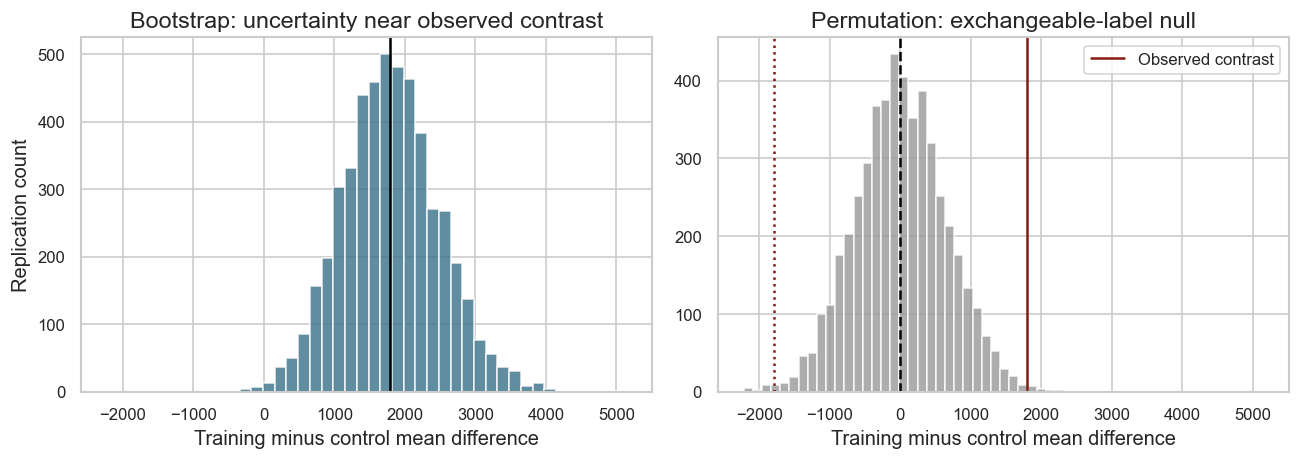

In [7]:
# Keep outcomes fixed; shuffle group labels under the null reference model.
def shuffle_difference(a, b, replications=5000, seed=1104):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    pool = np.concatenate([a, b])
    result = np.empty(replications)
    for i in range(replications):
        shuffled = rng.permutation(pool)
        result[i] = shuffled[:len(a)].mean() - shuffled[len(a):].mean()
    observed = a.mean() - b.mean()
    p_mc = (1 + np.sum(np.abs(result) >= abs(observed))) / (replications + 1)
    return result, float(p_mc)

permuted, permutation_p = shuffle_difference(training, control, B)
null_table = pd.DataFrame({"observed_difference": [welch.difference],
                           "replications": [B], "permutation_p_abs_two_sided": [permutation_p],
                           "welch_p_two_sided": [welch.p_two_sided]})
print(null_table.round(5).to_string(index=False))
null_table.to_csv(TABLES / "05_null_reference.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
axes[0].hist(boot, bins=35, color="#3a7188", alpha=.8)
axes[0].axvline(welch.difference, color="black")
axes[0].set(title="Bootstrap: uncertainty near observed contrast", ylabel="Replication count")
axes[1].hist(permuted, bins=35, color="#999999", alpha=.8)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(welch.difference, color="#851a10", label="Observed contrast")
axes[1].axvline(-welch.difference, color="#851a10", linestyle=":")
axes[1].set(title="Permutation: exchangeable-label null")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Training minus control mean difference")
fig.tight_layout()
show_save(fig, "06_bootstrap_vs_permutation.png")


### Checkpoint 5 — Bootstrap versus permutation
 Which graph addresses uncertainty around an estimate, and which addresses compatibility with a null model? Explain why a small p-value is not the probability that the null is true, does not measure practical importance, and does not prove generalization to all workers.


**Your response:** …


## 6 Different questions need different evidence
Choose **6A or 6B** for the ten-minute class application. Both code cells run if you use Run All, but only one written application is required during the session. These are exploratory analyses of actual records.

### 6A Two numerical variables: baseline earnings association
Among controls, compare 1974 and 1975 recorded earnings. Pearson r describes a linear association. Spearman rho describes an association between ranks and handles ordering differently, including tied zeros. Neither establishes that one year’s earnings caused another.

The optional Pearson p-value and Fisher interval use a conventional independent-pairs model; bivariate-normal assumptions for exact small-sample inference are questionable with many zeros and skewness. Use them cautiously and begin with the plot. The simple bootstrap here resamples each participant’s pair together.


 n_pairs  pearson_r pearson_model_p  pearson_fisher_low_95  pearson_fisher_high_95  spearman_rho
     260    0.67462        7.05e-36                0.60241                 0.73588       0.76677


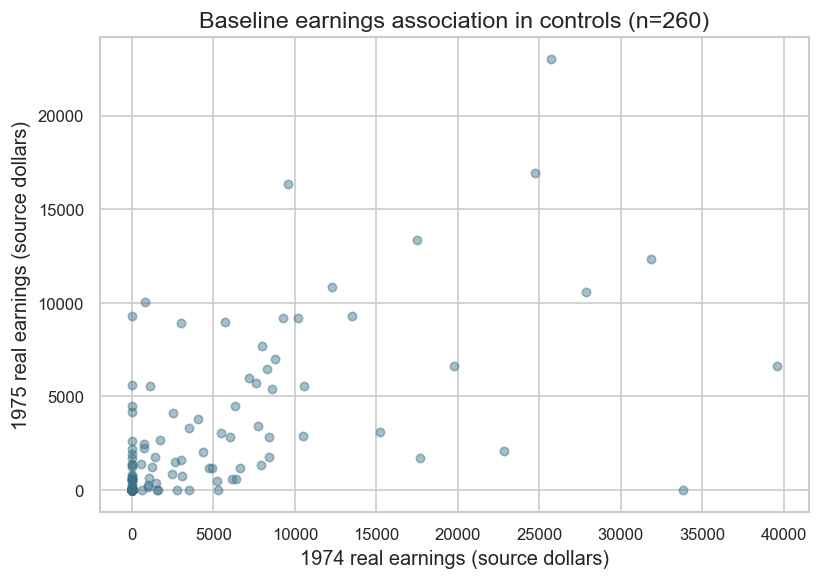

In [8]:
pairs = data.loc[data.treat == 0, ["re74", "re75"]].dropna()
pearson = stats.pearsonr(pairs.re74, pairs.re75)
spearman = stats.spearmanr(pairs.re74, pairs.re75)
pearson_ci = pearson.confidence_interval(confidence_level=.95)
association_table = pd.DataFrame({"n_pairs": [len(pairs)], "pearson_r": [pearson.statistic],
    "pearson_model_p": [pearson.pvalue], "pearson_fisher_low_95": [pearson_ci.low],
    "pearson_fisher_high_95": [pearson_ci.high], "spearman_rho": [spearman.statistic]})
print(association_table.to_string(index=False, formatters={"pearson_model_p": lambda value: f"{value:.3g}"}, float_format=lambda value: f"{value:.5f}"))
association_table.to_csv(TABLES / "06_association.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pairs.re74, pairs.re75, alpha=.45, s=25, color="#3a7188")
ax.set(xlabel="1974 real earnings (source dollars)", ylabel="1975 real earnings (source dollars)",
       title=f"Baseline earnings association in controls (n={len(pairs)})")
fig.tight_layout()
show_save(fig, "07_baseline_association.png")


**6A response:** State the unit, usable N, direction and strength of the pattern. Name one feature visible in the plot that matters for Pearson inference. Explain why a small p-value would not establish causality. Do not treat an arbitrary correlation benchmark as a universal definition of importance.

### 6B Two groups and a binary outcome: positive recorded earnings
Create `positive78 = re78 > 0`. This means **positive recorded earnings**, not a verified employment rate. Compare group proportions and their **percentage-point difference**.

The confidence interval below is a large-sample unpooled Wald approximation; the zero-difference z test uses a pooled null proportion. Inspect success/failure counts. For rare or small counts, consider more suitable interval/exact methods rather than reusing this approximation.


          successes    n  failures  proportion
group                                         
Control         168  260        92    0.646154
Training        140  185        45    0.756757
 training_pct  control_pct  difference_pp  low_95_pp  high_95_pp       z  p_two_sided
     75.67568     64.61538       11.06029    2.57479    19.54579 2.49106      0.01274


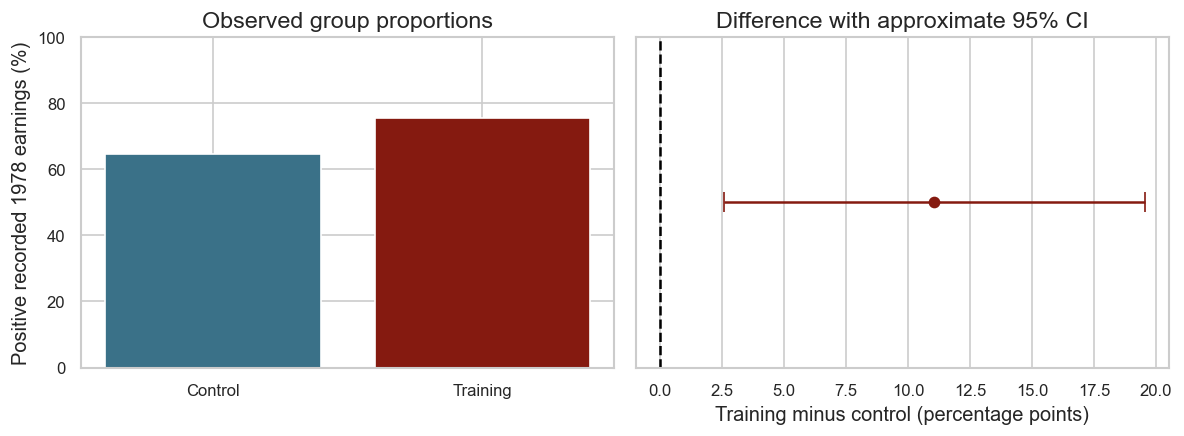

In [9]:
data["positive78"] = data["re78"].gt(0).astype(int)
counts = data.groupby("group")["positive78"].agg(successes="sum", n="size")
counts["failures"] = counts.n - counts.successes
counts["proportion"] = counts.successes / counts.n
n1, n0 = int(counts.loc["Training", "n"]), int(counts.loc["Control", "n"])
p1, p0 = counts.loc["Training", "proportion"], counts.loc["Control", "proportion"]
rd = p1 - p0
se_rd = np.sqrt(p1 * (1-p1) / n1 + p0 * (1-p0) / n0)
zcrit = stats.norm.ppf(.975)
pooled = (counts.successes.sum()) / counts.n.sum()
se_null = np.sqrt(pooled * (1-pooled) * (1/n1 + 1/n0))
z = rd / se_null
binary_table = pd.DataFrame({"training_pct": [p1*100], "control_pct": [p0*100],
    "difference_pp": [rd*100], "low_95_pp": [(rd-zcrit*se_rd)*100],
    "high_95_pp": [(rd+zcrit*se_rd)*100], "z": [z], "p_two_sided": [2*stats.norm.sf(abs(z))]})
print(counts.to_string())
print(binary_table.round(5).to_string(index=False))
counts.to_csv(TABLES / "07_binary_counts.csv")
binary_table.to_csv(TABLES / "07_binary_comparison.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(["Control", "Training"], [p0*100, p1*100], color=["#3a7188", "#851a10"])
axes[0].set(ylabel="Positive recorded 1978 earnings (%)", ylim=(0, 100), title="Observed group proportions")
axes[1].errorbar(rd*100, 0, xerr=zcrit*se_rd*100, fmt="o", capsize=6, color="#851a10")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(xlabel="Training minus control (percentage points)", yticks=[], title="Difference with approximate 95% CI")
fig.tight_layout()
show_save(fig, "08_proportion_comparison.png")


### 6B response
Report the difference in **percentage points**. Explain why this differs from a relative percentage change, what is lost when earnings are converted to a binary outcome, and why `re78 > 0` is not automatically a verified employment measure.

**Your response:** …

## 7 — Write one defensible result paragraph
Write **80–120 words** about the primary earnings comparison. Use this order:

1. **Question and design:** what was compared, and in what sample?
2. **Estimate:** direction, size, and source-dollar units.
3. **Uncertainty:** confidence interval and what it refers to.
4. **Test evidence:** p-value stated without “proves,” “accept,” or “probability the null is true.”
5. **Meaning and boundary:** practical interpretation plus one limitation.

> **Your paragraph:** …

**AI-use and verification statement:** Describe any permitted assistance and your checks, or write “No AI assistance used.”

### Connect the method to your own project

| Decision | Your project |
|---|---|
| Research question and claim purpose | … |
| Variables and types | … |
| Unit and dependence structure | … |
| Suitable summary and plot | … |
| Inferential method, if justified | … |
| Target quantity and assumptions | … |
| What the evidence cannot establish | … |

Do not force a test onto every project. A descriptive or qualitative study may instead explain what appropriate evidence would look like.

## 8 — Save and reproduce
Run all cells with the fixed seeds. Larger `B` reduces Monte Carlo noise; it does not reduce source bias. Do not vary seeds or specifications to chase a preferred p-value.

The next cell saves the prepared data, tables, figures, software versions, and verified source files in one ZIP bundle. Also save this notebook with your written responses.


In [10]:
data.to_csv(ROOT / "prepared_nsw.csv", index=False)
(ROOT / "environment.json").write_text(json.dumps({"python": sys.version.split()[0],
    "pandas": pd.__version__, "numpy": np.__version__, "scipy": scipy.__version__,
    "seaborn": sns.__version__, "B": B, "confidence": CONFIDENCE}, indent=2))
for item in manifest["files"]:
    assert hashlib.sha256((RAW / item["file"]).read_bytes()).hexdigest() == item["sha256"]
print("PASS raw hashes. No missing-value deletion or outcome winsorization applied.")
BUNDLE = ROOT / "inference_outputs.zip"
def export_bundle():
    with zipfile.ZipFile(BUNDLE, "w", zipfile.ZIP_DEFLATED) as bundle:
        for folder in [RAW, TABLES, FIGS]:
            for file in sorted(folder.glob("*")):
                if file.is_file():
                    bundle.write(file, str(file.relative_to(ROOT)))
        for file in [ROOT / "prepared_nsw.csv", ROOT / "environment.json"]:
            bundle.write(file, file.name)
    print("Download:", BUNDLE)
export_bundle()


PASS raw hashes. No missing-value deletion or outcome winsorization applied.


Download: C:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W11\inference_lab\inference_outputs.zip


## 9 Stretch reference: paired change and resampled association
### 9A Paired observations
A participant’s 1975 and 1978 earnings belong to the **same person**. Compute within-person differences before summarizing; treating the two columns as independent groups would ignore pairing.

The observed changes are not automatically training effects. Controls can change over time too. The paired analysis tests a different question from the between-group 1978 contrast.


In [11]:
paired_records = []
for label in ["Control", "Training"]:
    change = data.loc[data.group == label, "re78"] - data.loc[data.group == label, "re75"]
    se = change.std(ddof=1) / np.sqrt(len(change))
    critical = stats.t.ppf(.975, len(change)-1)
    test = stats.ttest_1samp(change, popmean=0)
    paired_records.append({"group": label, "n_pairs": len(change), "mean_within_person_change": change.mean(),
        "low_95": change.mean()-critical*se, "high_95": change.mean()+critical*se, "paired_p_two_sided": test.pvalue})
paired_table = pd.DataFrame(paired_records)
print(paired_table.to_string(index=False, formatters={"paired_p_two_sided": lambda value: f"{value:.3g}"}, float_format=lambda value: f"{value:.4f}"))
paired_table.to_csv(TABLES / "09_paired_change.csv", index=False)


   group  n_pairs  mean_within_person_change    low_95   high_95 paired_p_two_sided
 Control      260                  3287.8921 2547.8599 4027.9243           2.81e-16
Training      185                  4817.0882 3616.7113 6017.4651           2.22e-13


### 9B Bootstrap whole participant pairs for correlation
Preserve the association by resampling rows of `(re74, re75)` together. Resampling the two columns independently would destroy the observed relationship and approximate a different null operation.

The resulting percentile interval is an independent-participant approximation, not protection against dependence, sample selection, tied values or instability caused by influential observations.


In [12]:
rng_corr = np.random.default_rng(1105)
xy = pairs[["re74", "re75"]].to_numpy()
boot_r = np.empty(2000)
for i in range(len(boot_r)):
    sample = xy[rng_corr.integers(0, len(xy), size=len(xy))]
    boot_r[i] = np.corrcoef(sample[:, 0], sample[:, 1])[0, 1]
print("Pair-resampled Pearson r interval:", np.quantile(boot_r, [.025, .975]))
export_bundle()  # Refresh after optional outputs.


Pair-resampled Pearson r interval: [0.51811533 0.81702008]
Download: C:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W11\inference_lab\inference_outputs.zip


## References and interpretation guides
- [Rajeev Dehejia author data page](https://users.nber.org/~rdehejia/data/.nswdata2.html): original source files, variable order and sample distinction.
- LaLonde, R. J. (1986). Evaluating the Econometric Evaluations of Training Programs with Experimental Data. *American Economic Review*, 76, 604–620.
- Dehejia, R. H., and Wahba, S. (1999). Causal Effects in Nonexperimental Studies: Reevaluating the Evaluation of Training Programs. *JASA*, 94, 1053–1062.
- [SciPy Welch t test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [Pearson correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html), [permutation methods](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)
- [American Statistical Association statement on p-values](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)

Real observed records and their source are separate from simulated resamples. Standard analyses and graphs are reproducible from the embedded files. Data and documentation checked November 2026.
